https://github.com/iandriyash/ai-arhictect-2026-demo

# Домашнее задание: KNN-классификация

**Датасет:** витрина из 1-й промежуточной аттестации (`loan_overdue_mart.csv`).

**Цель:** бинарная классификация — предсказать факт просрочки (`is_overdue`).

Используем признаки, известные на момент выдачи кредита. Масштабируем их перед KNN, строим ROC и Precision-Recall, выбираем порог и считаем метрики на тесте.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay,
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score,
    roc_curve, precision_recall_curve,
)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

## 1. Целевая переменная и признаки

**Таргет:** `is_overdue` — 1, если по кредиту была хотя бы одна просрочка, иначе 0.

**Признаки:** доход, возраст, ставка, срок, продукт и статус занятости (dummy). Все известны на момент выдачи.

In [2]:
df = pd.read_csv("loan_overdue_mart.csv")
work = df[[
    "is_overdue", "annual_income", "customer_age",
    "interest_rate", "term_months", "loan_product_id", "employment_status_id",
]].dropna().copy()

work["product_2"] = (work["loan_product_id"] == 2).astype(int)
work["emp_2"] = (work["employment_status_id"] == 2).astype(int)
work["emp_3"] = (work["employment_status_id"] == 3).astype(int)
work["emp_4"] = (work["employment_status_id"] == 4).astype(int)

print("Строк:", len(work))
print(work["is_overdue"].value_counts(normalize=True).round(3))

Строк: 2477
is_overdue
0   0.794
1   0.206
Name: proportion, dtype: float64


## 2. Разделение и масштабирование

KNN считает расстояния, поэтому признаки нужно привести к одному масштабу.

In [3]:
feat_cols = [
    "annual_income", "customer_age", "interest_rate", "term_months",
    "product_2", "emp_2", "emp_3", "emp_4",
]
X = work[feat_cols]
y = work["is_overdue"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

print("Train:", X_train.shape, "Test:", X_test.shape)
print("Доля 1 в train:", y_train.mean().round(3))

Train: (1857, 8) Test: (620, 8)
Доля 1 в train: 0.206


## 3. Обучение KNN

In [4]:
knn = KNeighborsClassifier(n_neighbors=15)
knn.fit(X_train_s, y_train)

y_proba = knn.predict_proba(X_test_s)[:, 1]
print(f"ROC-AUC: {roc_auc_score(y_test, y_proba):.3f}")
print(f"PR-AUC:  {average_precision_score(y_test, y_proba):.3f}")

ROC-AUC: 0.588
PR-AUC:  0.254


## 4. ROC и Precision-Recall

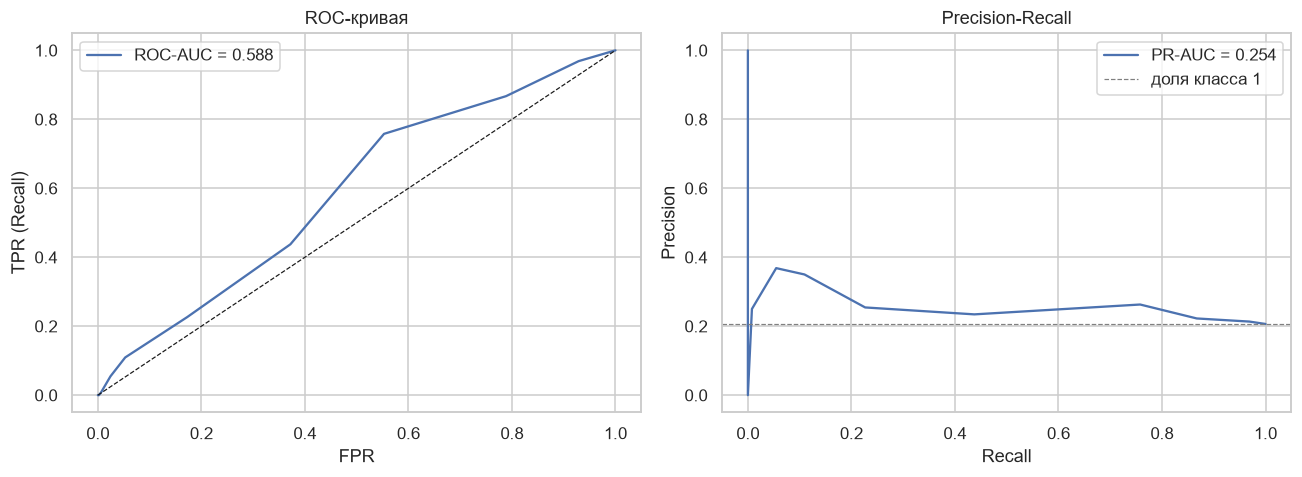

In [5]:
fpr, tpr, roc_thr = roc_curve(y_test, y_proba)
prec, rec, pr_thr = precision_recall_curve(y_test, y_proba)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].plot(fpr, tpr, label=f"ROC-AUC = {roc_auc_score(y_test, y_proba):.3f}")
axes[0].plot([0, 1], [0, 1], "k--", lw=0.8)
axes[0].set_xlabel("FPR")
axes[0].set_ylabel("TPR (Recall)")
axes[0].set_title("ROC-кривая")
axes[0].legend()

axes[1].plot(rec, prec, label=f"PR-AUC = {average_precision_score(y_test, y_proba):.3f}")
axes[1].axhline(y_test.mean(), color="gray", ls="--", lw=0.8, label="доля класса 1")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-Recall")
axes[1].legend()

plt.tight_layout()
plt.show()

## 5. Выбор порога

По умолчанию порог 0.5. При доле просрочек около 21% он часто даёт почти нулевой recall.  
Смотрим сетку порогов на тестовой выборке для иллюстрации. В боевой модели порог подбирают на валидации, не на тесте.

Добавляем ориентир: «ставить 1 всем» (precision = доля класса, recall = 1).

In [6]:
thresholds = [0.15, 0.20, 0.30, 0.40, 0.50]
rows = []
for t in thresholds:
    pred = (y_proba >= t).astype(int)
    rows.append({
        "порог": t,
        "accuracy": accuracy_score(y_test, pred),
        "precision": precision_score(y_test, pred, zero_division=0),
        "recall": recall_score(y_test, pred, zero_division=0),
        "f1": f1_score(y_test, pred, zero_division=0),
        "помечено": int(pred.sum()),
    })

# Ориентир: ставить 1 всем
all_one = {
    "порог": "всем 1",
    "accuracy": accuracy_score(y_test, np.ones_like(y_test)),
    "precision": precision_score(y_test, np.ones_like(y_test), zero_division=0),
    "recall": 1.0,
    "f1": f1_score(y_test, np.ones_like(y_test), zero_division=0),
    "помечено": len(y_test),
}
rows.append(all_one)

thr_df = pd.DataFrame(rows)
print(thr_df.round(3).to_string(index=False))

 порог  accuracy  precision  recall    f1  помечено
 0.150     0.511      0.263   0.758 0.390       369
 0.200     0.511      0.263   0.758 0.390       369
 0.300     0.703      0.254   0.227 0.240       114
 0.400     0.774      0.350   0.109 0.167        40
 0.500     0.790      0.250   0.008 0.015         4
всем 1     0.206      0.206   1.000 0.342       620


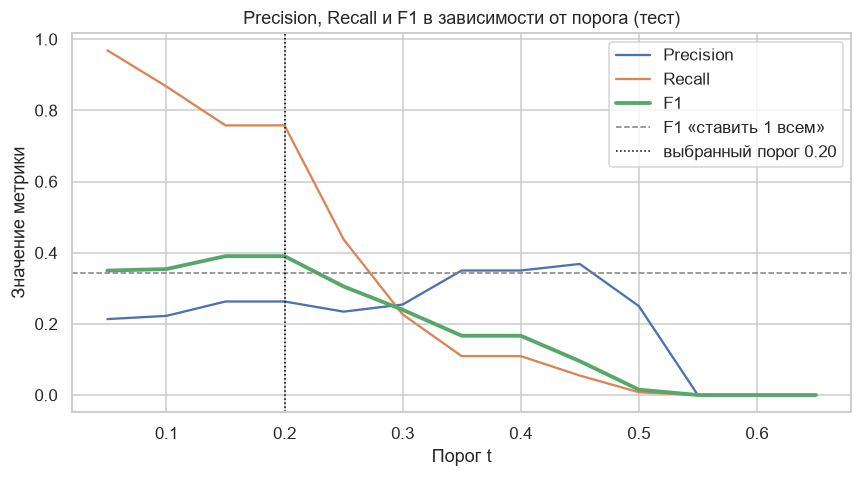

In [7]:
grid = np.arange(0.05, 0.66, 0.05)
curve = []
for t in grid:
    pred = (y_proba >= t).astype(int)
    curve.append({
        "порог": t,
        "precision": precision_score(y_test, pred, zero_division=0),
        "recall": recall_score(y_test, pred, zero_division=0),
        "f1": f1_score(y_test, pred, zero_division=0),
    })
curve = pd.DataFrame(curve)

f1_all_one = f1_score(y_test, np.ones_like(y_test))

plt.figure(figsize=(8, 4.5))
plt.plot(curve["порог"], curve["precision"], label="Precision")
plt.plot(curve["порог"], curve["recall"], label="Recall")
plt.plot(curve["порог"], curve["f1"], label="F1", lw=2.5)
plt.axhline(f1_all_one, color="gray", ls="--", lw=1, label="F1 «ставить 1 всем»")
plt.axvline(0.20, color="black", ls=":", lw=1, label="выбранный порог 0.20")
plt.xlabel("Порог t")
plt.ylabel("Значение метрики")
plt.title("Precision, Recall и F1 в зависимости от порога (тест)")
plt.legend()
plt.tight_layout()
plt.show()

**Выбор порога.**  
Беру порог **0.20**. Вероятности у KNN с k=15 кратны 1/15, поэтому пороги 0.15 и 0.20 дают одинаковые предсказания (отсюда две одинаковые строки в таблице). Среди проверенных порогов это лучший F1, и он выше, чем у правила «ставить 1 всем». При 0.3 и выше F1 падает ниже этого ориентира.  
На графике видно компромисс: при низком пороге recall высокий, а precision низкий; F1 максимален около 0.15–0.20 и при росте порога падает ниже ориентира «всем 1».  
Преимущество небольшое: при пороге 0.20 помечается около 60% кредитов, а precision лишь немного выше доли просрочек. К простому правилу модель добавляет немного.  
Порог смотрели на тесте только для иллюстрации. В реальной модели его подбирают на валидационной выборке.

## 6. Предсказания, матрица ошибок и метрики

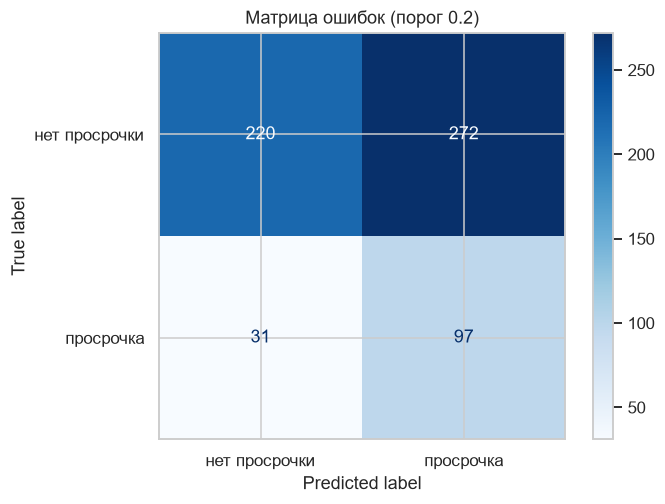

Accuracy:  0.511
Precision: 0.263
Recall:    0.758
F1:        0.390
ROC-AUC:   0.588


In [8]:
threshold = 0.20
y_pred = (y_proba >= threshold).astype(int)

cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(cm, display_labels=["нет просрочки", "просрочка"])
disp.plot(cmap="Blues")
plt.title(f"Матрица ошибок (порог {threshold})")
plt.show()

print(f"Accuracy:  {accuracy_score(y_test, y_pred):.3f}")
print(f"Precision: {precision_score(y_test, y_pred, zero_division=0):.3f}")
print(f"Recall:    {recall_score(y_test, y_pred, zero_division=0):.3f}")
print(f"F1:        {f1_score(y_test, y_pred, zero_division=0):.3f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, y_proba):.3f}")

In [9]:
# Для сравнения: payments_cnt неизвестен при выдаче, в модель его не берём
test_idx = y_test.index
auc_cnt = roc_auc_score(df.loc[test_idx, "is_overdue"], df.loc[test_idx, "payments_cnt"])
print(f"ROC-AUC по одному payments_cnt на тесте: {auc_cnt:.3f}")

ROC-AUC по одному payments_cnt на тесте: 0.640


## 7. Выводы

**Качество модели.**  
KNN на признаках, известных при выдаче, даёт на тесте ROC-AUC около 0.59 — чуть выше случайного (0.5). Оценка шумная: в тесте около 130 просрочек. Сильного разделения нет. Это согласуется с ПА-1: сырые признаки заёмщика слабо связаны с просрочкой. Для сравнения, один `payments_cnt` даёт заметно более высокий AUC (ячейка выше), но в модель его брать нельзя: число платежей неизвестно на момент выдачи и отражает длину окна наблюдения, а не качество заёмщика.

**Порог.**  
Порог 0.20 выбран по таблице на тесте: по F1 он лучше «ставить 1 всем», но разница небольшая, а помечается около 60% кредитов. При 0.3 и выше F1 падает ниже этого ориентира. Accuracy при низком пороге хуже, чем у правила «всем 0», но accuracy здесь не главный критерий из-за дисбаланса. В бою порог подбирают на валидации и с учётом цены ошибки.

**Зависимости.**  
У KNN нет коэффициентов, поэтому нельзя сказать, какой признак «главный». Модель использует локальные сочетания признаков, известных на выдаче. На этих данных этого недостаточно для сильного разделения классов.

**Ограничение.**  
KNN чувствителен к масштабу и к неинформативным признакам. Масштабирование сделано, но слабый сигнал ограничивает качество. Для кредитного скоринга дальше обычно переходят к логистической регрессии или деревьям.